In [1]:
import matplotlib.pyplot as plt
import numpy as np

from agents import EpsilonGreedyAgent, UCBAgent, GradientBanditAgent
from estimators import ConstantStepSizeEstimator, SampleAverageEstimator
from simulation import bandit_agent_run, run_simulation, run_experiment_parallel

%load_ext autoreload
%autoreload 2

# Stationary k-armed Bandit Testbed

### Set up Bandit with $q_{true} \sim \mathcal{N}(0,1)$

In [5]:
# Bandit parameters
k = 10  # number of arms in the bandit

# Simulation parameters
T = 3000  # number of timesteps played
R = 2000  # number of runs to play in the simulation

# $\epsilon$-greedy action-value method

### Compare different values of $\epsilon$ with Sample Average Estimator

In [6]:
%%time

# Agent parameters
epsilons = [0.0, 0.01, 0.1]

results = []
for i, epsilon in enumerate(epsilons):
    results.append(
        run_experiment_parallel(
            R, T, k, 
            estimator=SampleAverageEstimator, 
            epsilon=epsilon
        )
    )

CPU times: user 10.4 s, sys: 1.53 s, total: 11.9 s
Wall time: 2min 36s


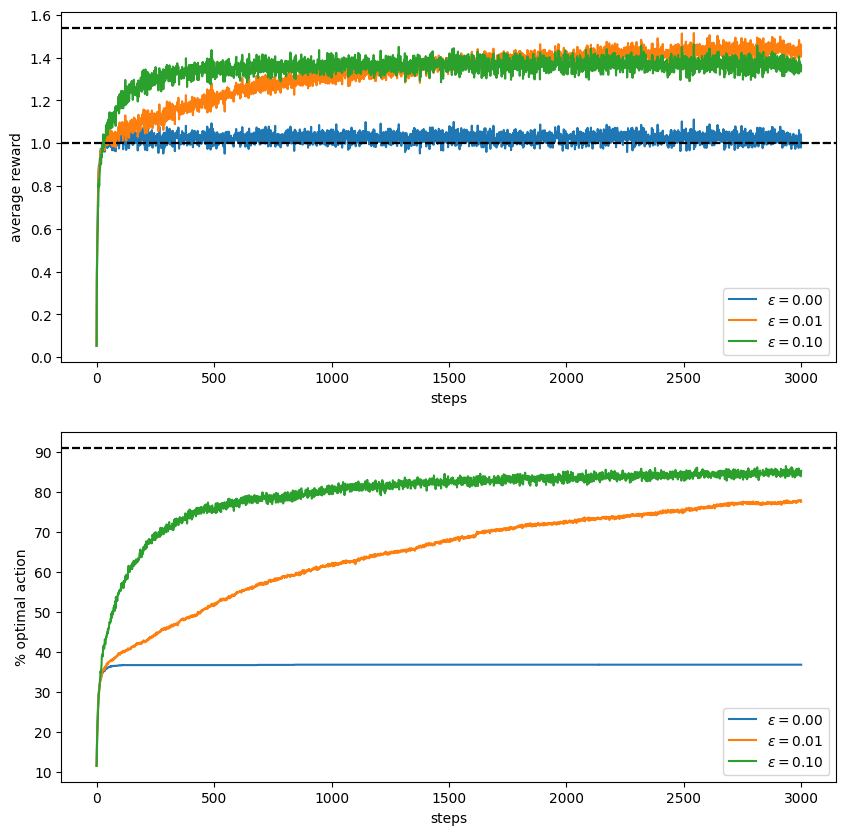

In [7]:
plt.figure(figsize=(10, 10))

plt.subplot(2, 1, 1)
for i, epsilon in enumerate(epsilons):
    plt.plot(results[i]["average_rewards"], label="$\\epsilon = %.02f$" % (epsilon))
    plt.axhline(y=1.54, color='k', linestyle='--')
    plt.axhline(y=1, color='k', linestyle='--')
plt.xlabel("steps")
plt.ylabel("average reward")
plt.legend()

plt.subplot(2, 1, 2)
for i, epsilon in enumerate(epsilons):
    plt.plot(results[i]["percent_optimal_actions"], label="$\\epsilon = %.02f$" % (epsilon))
    plt.axhline(y=91, color='k', linestyle='--')
plt.xlabel("steps")
plt.ylabel("% optimal action")
plt.legend()

plt.savefig("../images/figure_2_2.png", bbox_inches="tight")

### Constant Step Size Estimator with and without optimistic initial values

In [12]:
%%time

# Estimator and Agent parameters
estimators = [SampleAverageEstimator, ConstantStepSizeEstimator, ConstantStepSizeEstimator, ConstantStepSizeEstimator, ConstantStepSizeEstimator]
initial_qs = [0.0, 0.0, 0.0, 5.0, 5.0]
epsilons = [0.1, 0.1, 0.0, 0.1, 0.0]
labels = [
    "Sample Average ($\\epsilon = %.01f$)" % (epsilons[0]),
    "Realistic Constant Step-Size ($\\epsilon = %.01f$)" % (epsilons[1]),
    "Realistic, Greedy Constant Step-Size ($\\epsilon = %.01f$)" % (epsilons[2]),
    "Optimistic Constant Step-Size ($q_0 = %.0f$, $\\epsilon = %.01f$)" % (initial_qs[3], epsilons[3]),
    "Optimistic, Greedy Constant Step-Size ($q_0 = %.0f$, $\\epsilon = %.01f$)" % (initial_qs[4], epsilons[4])
]

results = []

for estimator, initial_q, epsilon in list(zip(estimators, initial_qs, epsilons)):
    results.append(
        run_experiment_parallel(
            R, T, k, 
            estimator, 
            EpsilonGreedyAgent,
            initial_q=initial_q,
            epsilon=epsilon
        )
    )

CPU times: user 18.9 s, sys: 2.74 s, total: 21.6 s
Wall time: 4min 32s


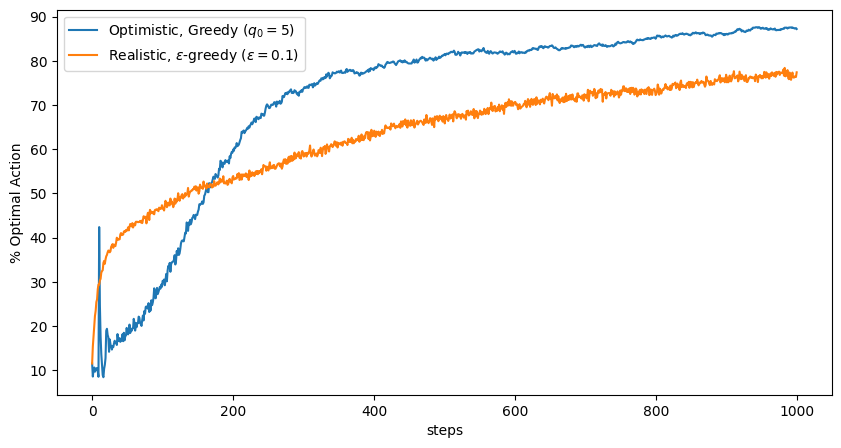

In [13]:
plt.figure(figsize=(10, 5))

plt.plot(results[4]["percent_optimal_actions"][0:1000], label="Optimistic, Greedy ($q_0 = %.0f$)" % (initial_qs[4]))
plt.plot(results[1]["percent_optimal_actions"][0:1000], label="Realistic, $\\epsilon$-greedy ($\\epsilon = %.01f$)" % (epsilons[1]))
plt.xlabel("steps")
plt.ylabel("% Optimal Action")
plt.legend()

plt.savefig("../images/figure_2_3.png", bbox_inches="tight")

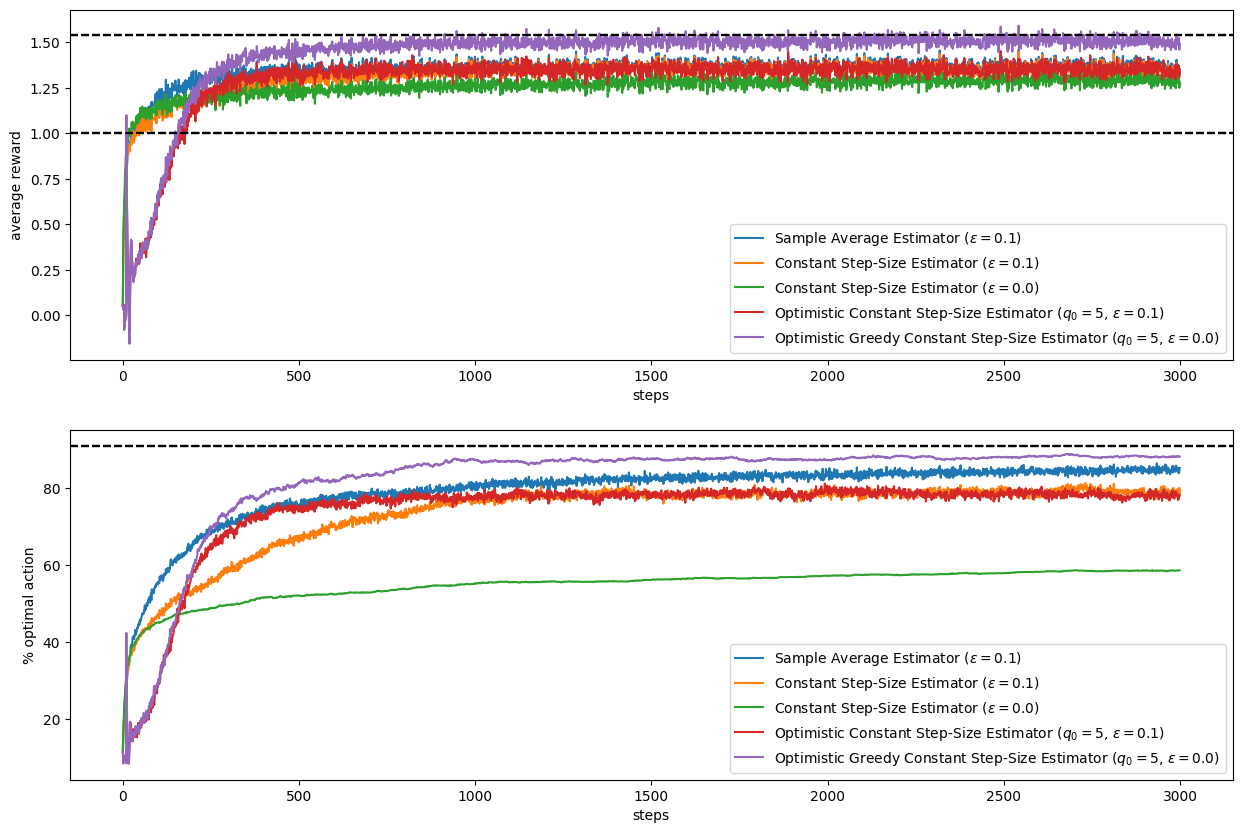

In [14]:
plt.figure(figsize=(15, 10))

plt.subplot(2, 1, 1)
for i, result in enumerate(results):
    plt.plot(result["average_rewards"], label=labels[i])
    plt.axhline(y=1.54, color='k', linestyle='--')
    plt.axhline(y=1, color='k', linestyle='--')
plt.xlabel("steps")
plt.ylabel("average reward")
plt.legend()

plt.subplot(2, 1, 2)
for i, result in enumerate(results):
    plt.plot(result["percent_optimal_actions"], label=labels[i])
    plt.axhline(y=91, color='k', linestyle='--')
plt.xlabel("steps")
plt.ylabel("% optimal action")
plt.legend()


# UCB

In [39]:
%%time

# Estimator and Agent parameters
estimators = [SampleAverageEstimator, SampleAverageEstimator, ConstantStepSizeEstimator, ConstantStepSizeEstimator, ConstantStepSizeEstimator]
agents =     [EpsilonGreedyAgent,     UCBAgent,               EpsilonGreedyAgent,        UCBAgent,                  UCBAgent]
initial_qs = [0.0,                    0.0,                    5.0,                       0.0,                       5.0]
epsilons =   [0.1,                    None,                   0.0,                       None,                      None]
cs =         [None,                   2.0,                    None,                      2.0,                       2.0]
labels = [
    "Epsilon Greedy w/ Sample Average ($\\epsilon = %.01f$)" % (epsilons[0]),
    "UCB w/ Sample Average ($c = %.01f$)" % (cs[1]),
    "Greedy w/ Optimistic Constant Step-Size Estimator ($q_0 = %.01f, \\alpha = 0.1$)" % (initial_qs[2]),
    "UCB w/ Realistic Constant Step-Size Estimator ($q_0 = %.01f, \\alpha = 0.1, c = %.01f$)" % (initial_qs[3], cs[3]),
    "UCB w/ Optimistic Constant Step-Size Estimator ($q_0 = %.01f, \\alpha = 0.1, c = %.01f$)" % (initial_qs[4], cs[4]),
]

results = []

for estimator, agent, initial_q, epsilon, c in list(zip(estimators, agents, initial_qs, epsilons, cs)):
    results.append(
        run_experiment_parallel(
            R, T, k, 
            estimator, 
            agent,
            initial_q=initial_q,
            epsilon=epsilon,
            c=c
        )
    )

CPU times: user 7.8 s, sys: 1.25 s, total: 9.05 s
Wall time: 2min 4s


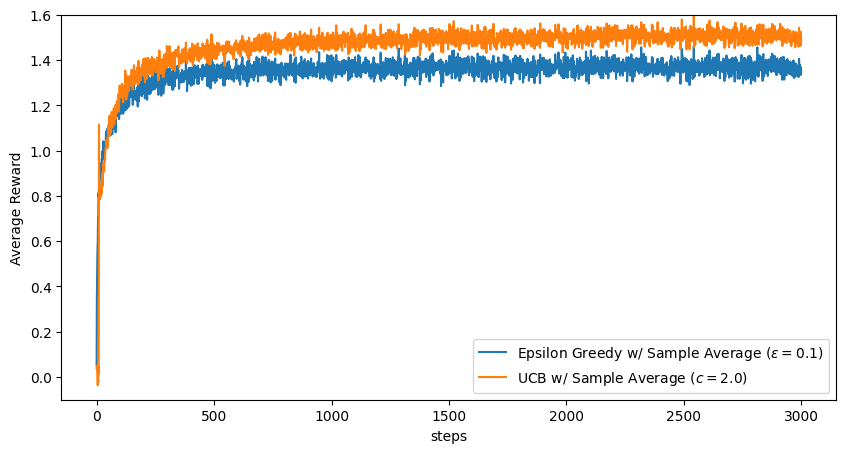

In [57]:
plt.figure(figsize=(10, 5))

for i, result in enumerate(results[0:2]):
    plt.plot(result["average_rewards"], label=labels[i])
plt.ylim(-0.1, 1.6)
plt.xlabel("steps")
plt.ylabel("Average Reward")
plt.legend()

plt.savefig("../images/figure_2_4.png", bbox_inches="tight")

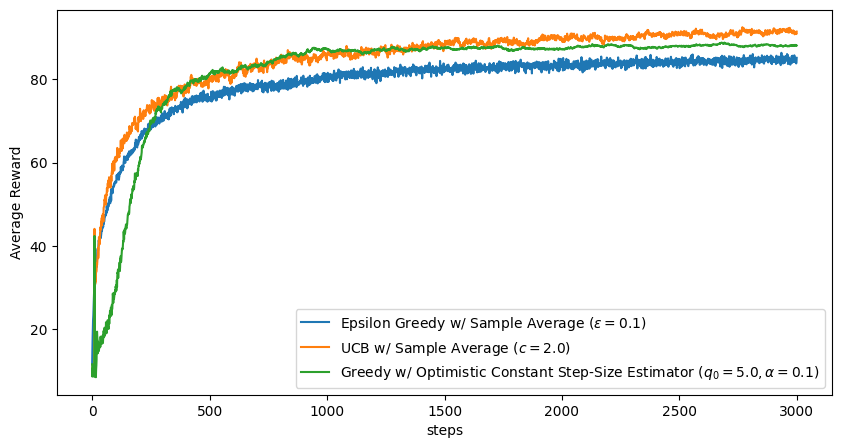

In [60]:
plt.figure(figsize=(10, 5))

for i, result in enumerate(results[0:3]):
    plt.plot(result["percent_optimal_actions"], label=labels[i])
plt.xlabel("steps")
plt.ylabel("Average Reward")
plt.legend()

plt.savefig("../images/figure_2_4_poa.png", bbox_inches="tight")

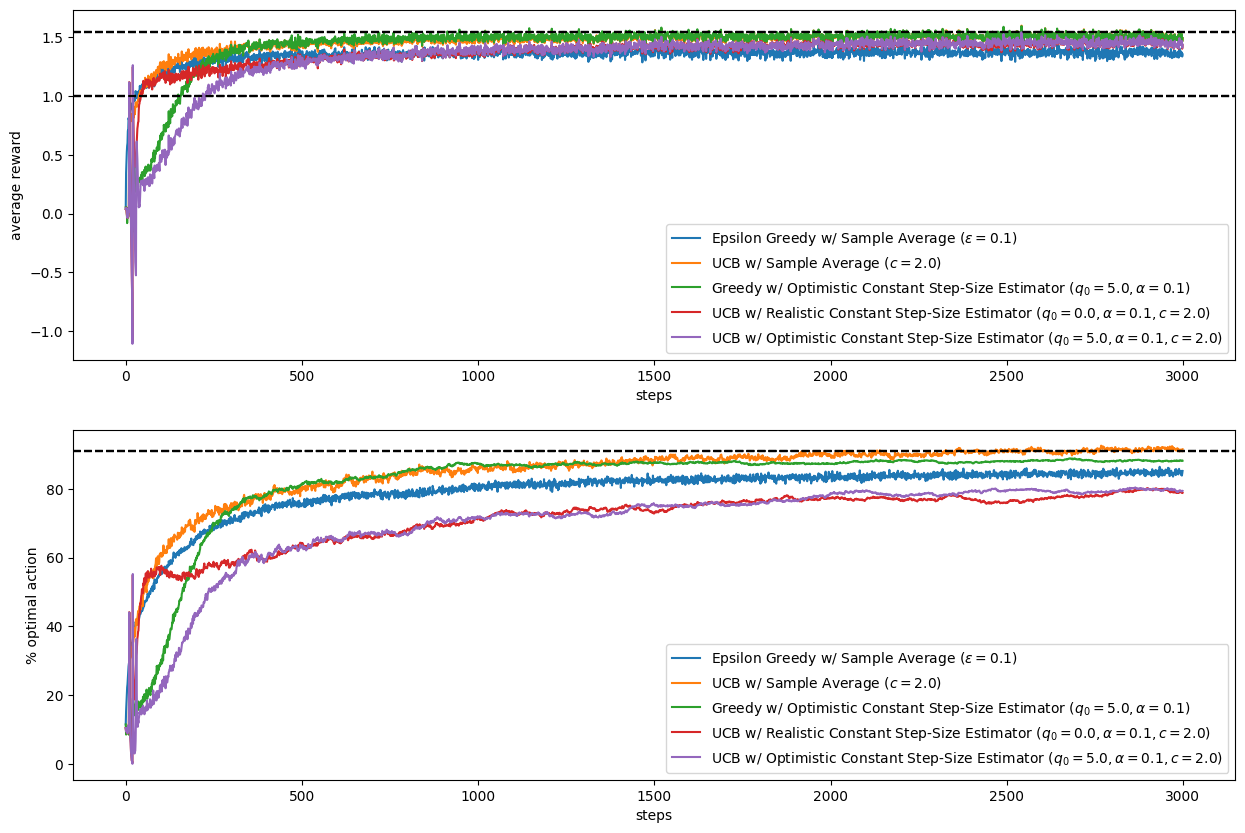

In [41]:
plt.figure(figsize=(15, 10))

plt.subplot(2, 1, 1)
for i, result in enumerate(results):
    plt.plot(result["average_rewards"], label=labels[i])
    plt.axhline(y=1.54, color='k', linestyle='--')
    plt.axhline(y=1, color='k', linestyle='--')
plt.xlabel("steps")
plt.ylabel("average reward")
plt.legend()

plt.subplot(2, 1, 2)
for i, result in enumerate(results):
    plt.plot(result["percent_optimal_actions"], label=labels[i])
    plt.axhline(y=91, color='k', linestyle='--')
plt.xlabel("steps")
plt.ylabel("% optimal action")
plt.legend()